# Decision Tree Classification — Complete Learning Notes

## 1. What is a Decision Tree?

A Decision Tree is a **supervised machine learning algorithm** used for both classification and regression.

It learns patterns from training data by repeatedly splitting the data using feature-based conditions.

For classification, it predicts a class such as Pass/Fail or Malignant/Benign.

### Main components

- **Root node:** The first node containing the entire training dataset.
- **Decision node:** A node where a condition is evaluated.
- **Branch:** The outcome of a condition, such as True or False.
- **Leaf node:** A terminal node that produces the final prediction.

Example:

```text
             Study hours <= 2.5?
                  /       \
                Yes        No
                /           \
             Fail           Pass
```

If a student studies 2 hours, the prediction is Fail. If a student studies 4 hours, the prediction is Pass.

This is an illustrative tree, not a guarantee about real student outcomes.

---

## 2. CART Algorithm

**CART stands for Classification and Regression Trees.**

It is a tree-building algorithm that constructs a decision tree by repeatedly finding useful splits in the training data.

### How CART works

1. Start with all training samples in the root node.
2. Generate candidate splits using different features and thresholds.
3. Calculate the quality of each candidate split using a splitting criterion.
4. Select the best split according to that criterion.
5. Divide the data into child nodes.
6. Repeat the process recursively for child nodes.
7. Stop when a stopping condition is reached.

CART makes a locally greedy decision: it chooses the best split at the current node rather than searching exhaustively for the globally optimal complete tree.

### Model vs. algorithm vs. criterion

- **Decision Tree:** The learned model consisting of nodes, branches, and leaves.
- **CART:** The algorithm used to construct the tree.
- **Gini impurity:** One criterion used to evaluate candidate classification splits.

The algorithm uses the criterion to decide which split to select.

---

## 3. Gini Impurity

Gini impurity measures how mixed the classes are in a node.

### Formula

$$
Gini = 1 - \sum_{i=1}^{k} p_i^2
$$

Where:

- $p_i$ is the proportion of samples belonging to class $i$.
- $k$ is the number of classes.

### Example: Eight students

Suppose we have:

- 3 Fail students
- 5 Pass students

The parent node's Gini impurity is:

$$
Gini = 1 - \left(\frac{3}{8}\right)^2 - \left(\frac{5}{8}\right)^2
$$

$$
Gini = 1 - 0.140625 - 0.390625
$$

$$
\boxed{Gini = 0.46875}
$$

### Interpretation

- Gini = 0: The node is pure; all samples belong to one class.
- Higher Gini: The node has a more mixed class distribution.
- For binary classification, the maximum Gini is 0.5, achieved when both classes are equally represented.

The $1-$ in the formula subtracts the probability of selecting two samples from the same class from 1. It gives a measure of class mixing.

---

## 4. How CART Selects the Best Split

CART considers candidate splits across different features and thresholds.

For example:

- `study_hours <= 2.5`
- `attendance <= 67.5`
- `mock_score <= 60`

These thresholds are illustrative.

For a numerical feature, CART sorts the distinct observed values and considers candidate thresholds between consecutive distinct values.

Suppose the distinct study-hour values are:

$$
1,\ 2,\ 3,\ 4,\ 5,\ 6
$$

Possible midpoint thresholds are:

$$
1.5,\ 2.5,\ 3.5,\ 4.5,\ 5.5
$$

For each candidate, CART divides the samples into left and right child nodes and evaluates the resulting impurity.

### Weighted Gini Impurity

The weighted Gini impurity of a split is:

$$
Gini_{\text{split}} =
\frac{N_L}{N}Gini_L +
\frac{N_R}{N}Gini_R
$$

Where:

- $N$ = total samples in the parent node.
- $N_L$ = samples in the left child.
- $N_R$ = samples in the right child.
- $Gini_L$ and $Gini_R$ = child-node impurities.

The weights account for the different sizes of the child nodes.

### Candidate A: Study hours <= 2.5

Left child:

- 3 Fail
- 0 Pass

Right child:

- 0 Fail
- 5 Pass

Both children are pure, so:

$$
Gini_L = 0,\qquad Gini_R = 0
$$

$$
Gini_{\text{split}} =
\frac{3}{8}(0) + \frac{5}{8}(0) = 0
$$

The Gini reduction is:

$$
\Delta Gini = Gini_{\text{parent}} - Gini_{\text{split}}
$$

$$
\Delta Gini = 0.46875 - 0
= \boxed{0.46875}
$$

### Candidate B: Study hours <= 3.5

Left child:

- 3 Fail
- 1 Pass

Right child:

- 0 Fail
- 4 Pass

The left child has:

$$
Gini_L = 1 - \left(\frac{3}{4}\right)^2
- \left(\frac{1}{4}\right)^2
= 0.375
$$

The right child is pure:

$$
Gini_R = 0
$$

Weighted Gini:

$$
Gini_{\text{split}} =
\frac{4}{8}(0.375) + \frac{4}{8}(0)
= 0.1875
$$

Gini reduction:

$$
\Delta Gini = 0.46875 - 0.1875
= \boxed{0.28125}
$$

### Comparison

| Candidate | Weighted Gini | Gini reduction |
|---|---:|---:|
| Study hours <= 2.5 | 0 | 0.46875 |
| Study hours <= 3.5 | 0.1875 | 0.28125 |

Candidate A wins because it produces the larger reduction in impurity.

**Important:** CART also compares candidates from other features. The best root split is the one that performs best among the candidates considered. If multiple splits tie, the implementation may choose one according to its tie-breaking behavior.

---

## 5. Entropy and Information Gain

Entropy is another measure of impurity or uncertainty in a node.

### Entropy formula

$$
H(S) = -\sum_{i=1}^{k} p_i \log_2(p_i)
$$

For our parent node containing 3 Fail and 5 Pass students:

$$
H(S) = -
\left[
\frac{3}{8}\log_2\left(\frac{3}{8}\right)
+
\frac{5}{8}\log_2\left(\frac{5}{8}\right)
\right]
$$

$$
\boxed{H(S) \approx 0.9544}
$$

For binary classification using base-2 logarithms:

- Entropy = 0: Pure node.
- Entropy = 1: Equal proportions of the two classes.

### Weighted entropy after a split

$$
H_{\text{split}} =
\frac{N_L}{N}H_L +
\frac{N_R}{N}H_R
$$

### Information Gain

Information Gain measures how much entropy is reduced by a split.

$$
IG = H_{\text{parent}} - H_{\text{split}}
$$

For the threshold `study_hours <= 2.5`, both child nodes are pure:

$$
H_{\text{split}} = 0
$$

Therefore:

$$
IG = 0.9544 - 0
= \boxed{0.9544}
$$

For the threshold `study_hours <= 3.5`, the weighted child entropy is approximately 0.4056:

$$
IG = 0.9544 - 0.4056
\approx \boxed{0.5488}
$$

The first split has greater Information Gain.

### Gini vs. Entropy

| Gini approach | Entropy approach |
|---|---|
| Measures class impurity | Measures class uncertainty |
| Uses $1-\sum p_i^2$ | Uses $-\sum p_i\log_2(p_i)$ |
| Selects the lowest weighted Gini | Selects the highest Information Gain |
| No logarithms required | Uses logarithms |

Both help evaluate candidate splits, but their mathematical formulas differ.

Classic CART classification trees use Gini or twoing criteria, while ID3 and C4.5 use entropy-based criteria. Scikit-learn's CART-style classifier also supports entropy and log-loss criteria.

---

## 6. Other Decision Tree Algorithms

| Algorithm | Main idea |
|---|---|
| CART | Binary splits; Gini commonly used for classification |
| ID3 | Uses Information Gain; originally designed mainly for categorical features |
| C4.5 | Uses Gain Ratio and supports continuous features |
| C5.0 | Successor to C4.5, with efficiency improvements and additional capabilities |

Gini and entropy are splitting criteria, not tree-building algorithms by themselves.

---

## 7. Overfitting in Decision Trees

Overfitting happens when a model learns the training data too closely, including noise and accidental patterns, and performs poorly on unseen data.

A very deep tree may achieve nearly perfect training accuracy but have lower test accuracy.

| Tree complexity | Possible behavior |
|---|---|
| Too simple | Underfitting: misses important patterns |
| Suitable complexity | Learns useful patterns and generalizes better |
| Too complex | Overfitting: memorizes training examples |

The goal is not to maximize training accuracy at any cost. The goal is to generalize well to unseen samples.

---

## 8. Stopping Conditions and Hyperparameters

### `max_depth`

Limits the maximum depth of the tree.

- Lower value: simpler tree, but potentially underfits.
- Higher value: more complex tree, potentially overfits.
- `None`: no explicit maximum-depth restriction.

The root is at depth 0.

### `min_samples_split`

The minimum number of training samples required for a node to be eligible for splitting.

For example, with `min_samples_split=4`, a node with 3 samples cannot be split.

### `min_samples_leaf`

The minimum number of training samples required in each leaf.

For example, with `min_samples_leaf=2`, a candidate split that produces a child with only one sample is disallowed.

| Parameter | Purpose |
|---|---|
| `max_depth` | Limits tree depth |
| `min_samples_split` | Controls eligibility to split a node |
| `min_samples_leaf` | Prevents very small leaves |

These parameters constrain tree growth and can help reduce overfitting.

---

## 9. Pruning

Pruning simplifies a tree by removing branches that do not provide enough predictive benefit.

### Pre-pruning

Restricts growth during training using parameters such as `max_depth` and `min_samples_leaf`.

### Post-pruning

Grows a tree and then removes branches to simplify it.

One method is cost-complexity pruning:

$$
R_\alpha(T) = R(T) + \alpha |T|
$$

Where:

- $T$ is the tree.
- $R(T)$ measures its risk or error under the chosen pruning formulation.
- $|T|$ is the number of leaf nodes.
- $\alpha$ controls the complexity penalty.

In scikit-learn, `ccp_alpha` controls cost-complexity pruning. A larger value generally favors simpler trees.

The appropriate value should be selected using validation data or cross-validation.

---

## 10. How a Trained Decision Tree Makes Predictions

During training, the algorithm learns the tree structure and its splitting rules.

During prediction:

1. A new sample enters the root node.
2. Its feature value is compared with the node's threshold.
3. The sample follows the corresponding branch.
4. This repeats until the sample reaches a leaf.
5. The leaf determines the predicted class.

If a leaf contains 7 benign and 3 malignant training samples, the predicted class would normally be benign.

The leaf's class proportions may also be used to estimate class probabilities.

**Key distinction:**

- `fit()` learns the tree.
- `predict()` follows the learned tree.
- Gini or entropy is used during training to evaluate candidate splits; it is not recalculated to choose the path for each new prediction.

---

## 11. Practical Exercise: Breast Cancer Classification

We used scikit-learn's built-in Breast Cancer Wisconsin dataset.

### Dataset

- 569 samples.
- 30 input features.
- Target: malignant or benign.
- `0` = malignant.
- `1` = benign.

We created a pandas DataFrame and inspected its shape, target distribution, data types, and missing values.

### Step 1: Import libraries

```python
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
```

### Step 2: Load the dataset

```python
data = load_breast_cancer()

df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df["target"] = data.target

df.head()
```

### Step 3: Inspect the dataset

```python
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

df.info()
```

### Step 4: Separate features and target

```python
X = df.drop(columns=["target"])
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)
```

- `X`: the 30 input measurements.
- `y`: the target labels.

### Step 5: Train-test split

```python
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
```

- `test_size=0.2`: approximately 80% training and 20% testing.
- `random_state=42`: makes the randomized split reproducible.
- `stratify=y`: approximately preserves class proportions in both sets.

The test set is kept separate from model training and hyperparameter selection.

### Step 6: Create the model

```python
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
```

- `criterion="gini"`: uses Gini impurity to evaluate candidate splits.
- `random_state=42`: makes randomized aspects of training reproducible.

We did not set `max_depth`, so it defaults to `None`.

Decision Trees generally do not require feature scaling because they split using feature thresholds rather than distances.

### Step 7: Train the model

```python
model.fit(X_train, y_train)
```

The library performs the split search, calculates impurity, builds child nodes recursively, and stores the learned tree in `model`.

### Step 8: Predict on test data

```python
y_pred = model.predict(X_test)

print("First 10 actual values:", y_test.iloc[:10].tolist())
print("First 10 predictions:", y_pred[:10])
```

The model follows the learned tree rules for each test sample.

### Step 9: Inspect the tree

```python
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())
```

These methods return the trained tree's maximum depth and number of leaf nodes.

### Step 10: Visualize the tree

```python
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Malignant", "Benign"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()
```

How to interpret the visualization:

- `feature <= threshold`: the splitting condition.
- `gini`: impurity at that node.
- `samples`: number of training samples reaching that node.
- `value`: class counts at that node.
- `class`: predicted class at that node.
- Colors: indicate the predicted class and node purity.

Our visualization showed `worst radius` as the root feature. CART selected it because its chosen split performed best among the candidates considered at that node, subject to the model settings.

This does not mean `worst radius` is always the best feature for every dataset or tree.

### Step 11: Evaluate predictions

```python
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"]
    )
)
```

The evaluation metrics are:

**Accuracy**

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

Measures the proportion of correct predictions.

**Precision**

$$
Precision = \frac{TP}{TP+FP}
$$

Measures the proportion of predicted positives that are actually positive.

**Recall**

$$
Recall = \frac{TP}{TP+FN}
$$

Measures the proportion of actual positives correctly identified.

**F1-score**

$$
F1 = 2 \times
\frac{Precision \times Recall}{Precision + Recall}
$$

Balances precision and recall.

Where:

- $TP$ = True Positives.
- $TN$ = True Negatives.
- $FP$ = False Positives.
- $FN$ = False Negatives.

The confusion matrix displays actual versus predicted class counts. Scikit-learn orders the classes as `0` then `1`, meaning malignant then benign for this dataset.

For medical classification, malignant-class recall deserves particular attention. These metrics alone do not establish clinical suitability.

We added these metrics to the code but did not record the numerical output in these notes.

---

## 12. Feature Importance

Decision Trees can estimate feature importance based on how much a feature contributes to reducing the chosen impurity criterion across the tree, weighted by the samples reaching the splits.

For example:

```python
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance.head(10))
```

This displays the ten features with the highest impurity-based importance in the trained tree.

Feature importance is model-specific. It does not prove that a feature causes the outcome, and importance can be distributed among correlated features.

---

## 13. Key Takeaways

1. CART builds a Decision Tree by repeatedly selecting useful splits.
2. Gini impurity measures class mixing in a node.
3. Weighted Gini evaluates the child nodes created by a split.
4. Entropy and Information Gain provide an alternative way to evaluate splits.
5. Recursive splitting continues until a stopping condition is reached.
6. Excessively complex trees can overfit.
7. Growth parameters and pruning help control complexity.
8. During prediction, a sample follows the learned conditions until it reaches a leaf.
9. Scikit-learn implements the training and prediction logic; we do not calculate every split manually.
10. The model should be evaluated on held-out data, and hyperparameters should be selected without using the test set.

**Final summary:** CART is the tree-building procedure, Gini or another supported criterion evaluates candidate splits, and the resulting Decision Tree is the trained model used to make predictions.

In [2]:
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [3]:
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

df.info()

Dataset shape: (569, 31)

Target distribution:
target
1    357
0    212
Name: count, dtype: int64

Missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569

In [5]:
X = df.drop(columns=["target"])
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [7]:
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

In [8]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [9]:
y_pred = model.predict(X_test)

print("First 10 actual values:", y_test.iloc[:10].tolist())
print("First 10 predictions:", y_pred[:10])

First 10 actual values: [0, 1, 0, 1, 0, 1, 1, 0, 0, 0]
First 10 predictions: [0 1 0 1 0 1 1 0 0 0]


In [10]:
# for checking trees structure
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())

Tree depth: 7
Number of leaves: 19


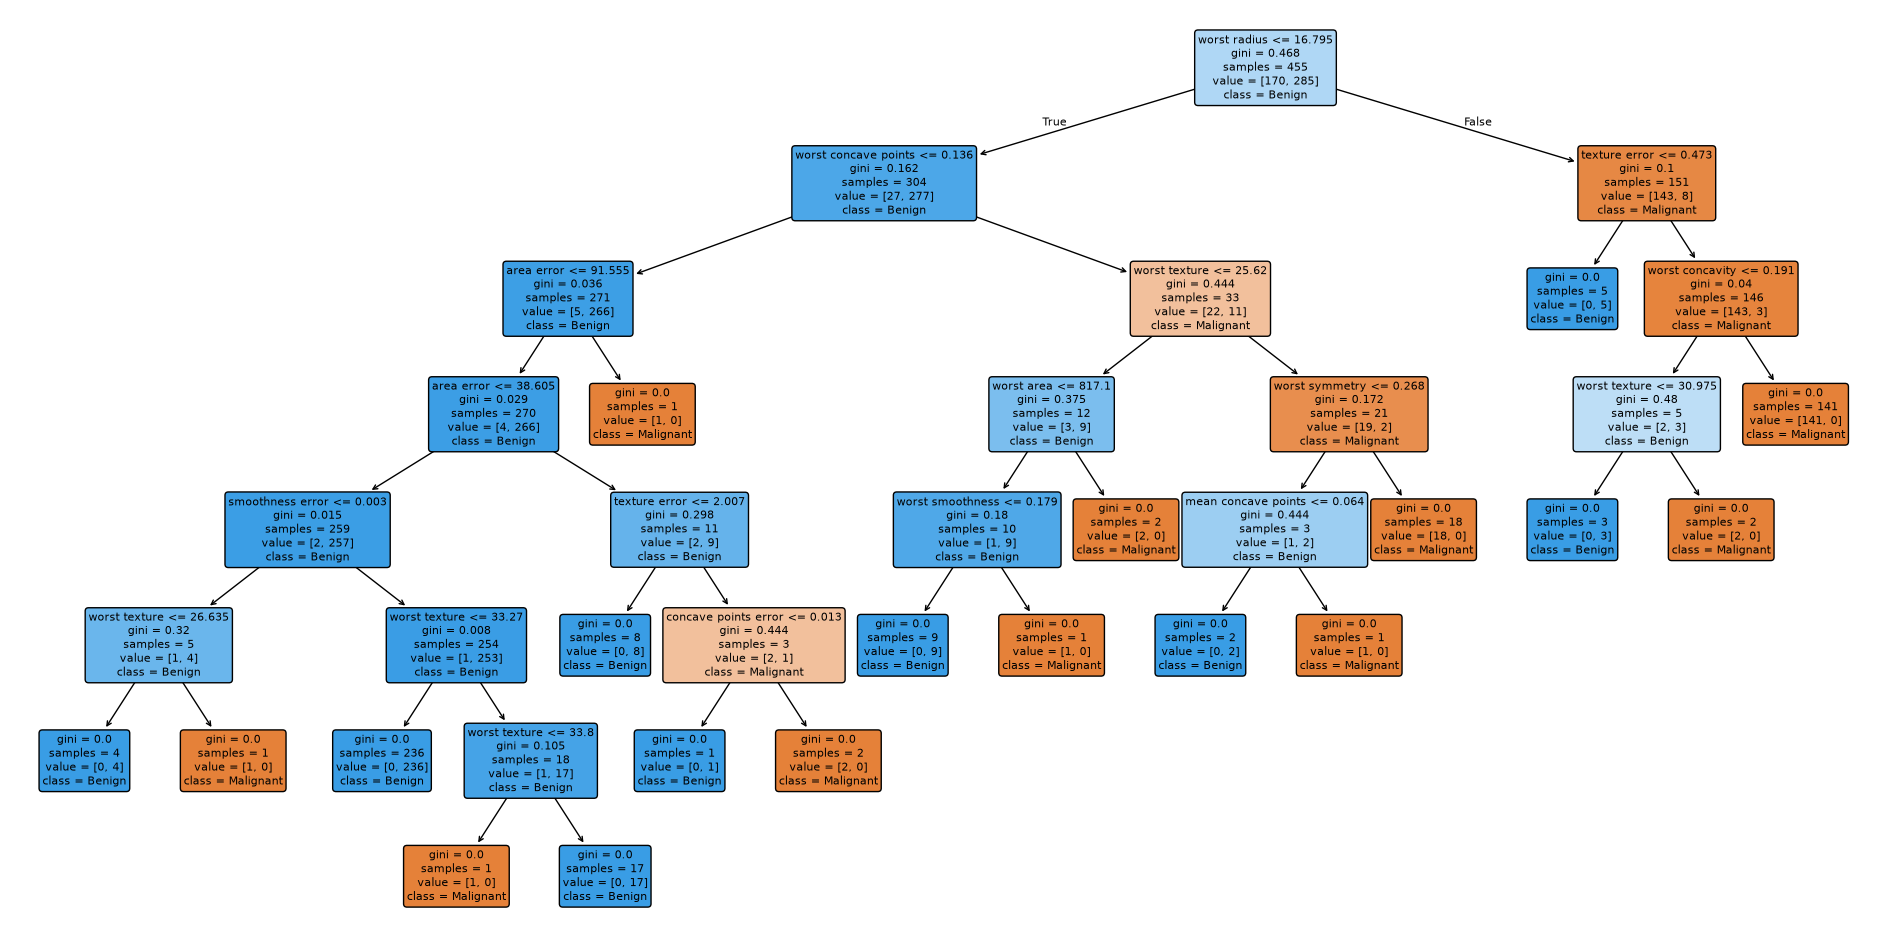

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Malignant", "Benign"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

In [12]:
tree = model.tree_

print("Root feature:", X.columns[tree.feature[0]])
print("Root threshold:", tree.threshold[0])
print("Gini impurity:", tree.impurity[0])
print("Samples:", tree.n_node_samples[0])
print("Class counts [Malignant, Benign]:", tree.value[0])

Root feature: worst radius
Root threshold: 16.795000076293945
Gini impurity: 0.46805941311435817
Samples: 455
Class counts [Malignant, Benign]: [[0.37362637 0.62637363]]


In [13]:

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)


print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)


print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"]
    )
)


Accuracy: 0.9122807017543859

Confusion Matrix:
 [[39  3]
 [ 7 65]]

Classification Report:

              precision    recall  f1-score   support

   Malignant       0.85      0.93      0.89        42
      Benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



In [14]:
print(f"\n Accuracy :{accuracy_score(y_test,y_pred)}")


 Accuracy :0.9122807017543859


# Decision Tree — All Important Formulas

## 1. Gini Impurity

Measures how mixed the classes are in a node.

**Formula:**

$$
Gini = 1 - \sum_{i=1}^{k} p_i^2
$$

Where:
- $p_i$ = proportion of samples belonging to class $i$
- $k$ = number of classes

**Example:** 3 Fail and 5 Pass students.

$$
Gini = 1 - \left(\frac{3}{8}\right)^2 - \left(\frac{5}{8}\right)^2
$$

$$
Gini = 1 - 0.140625 - 0.390625
$$

$$
\boxed{Gini = 0.46875}
$$

A pure node has Gini impurity equal to $0$.

---

## 2. Weighted Gini Impurity

Measures the combined impurity of the child nodes after a split, accounting for their sizes.

**Formula:**

$$
Gini_{\text{split}} =
\frac{N_L}{N}Gini_L +
\frac{N_R}{N}Gini_R
$$

Where:
- $N$ = number of samples in the parent node
- $N_L$ = number of samples in the left child
- $N_R$ = number of samples in the right child
- $Gini_L$ = Gini impurity of the left child
- $Gini_R$ = Gini impurity of the right child

**Example:** A split creates two pure groups containing 3 and 5 students.

$$
Gini_{\text{split}} =
\frac{3}{8}(0) + \frac{5}{8}(0)
$$

$$
\boxed{Gini_{\text{split}} = 0}
$$

---

## 3. Gini Reduction

Measures how much impurity decreases after a split.

**Formula:**

$$
\Delta Gini =
Gini_{\text{parent}} - Gini_{\text{split}}
$$

**Example:**

$$
\Delta Gini = 0.46875 - 0
$$

$$
\boxed{\Delta Gini = 0.46875}
$$

For a given parent node, CART using Gini selects a candidate split with the lowest weighted Gini, equivalently the greatest Gini reduction.

---

## 4. Entropy

Measures uncertainty or class mixing in a node.

**Formula:**

$$
H(S) = -\sum_{i=1}^{k} p_i \log_2(p_i)
$$

Where:
- $p_i$ = proportion of samples belonging to class $i$
- $k$ = number of classes
- $\log_2$ = logarithm with base 2

**Example:** 3 Fail and 5 Pass students.

$$
H(S) =
-\left[
\frac{3}{8}\log_2\left(\frac{3}{8}\right)
+
\frac{5}{8}\log_2\left(\frac{5}{8}\right)
\right]
$$

$$
\boxed{H(S) \approx 0.9544}
$$

A pure node has entropy equal to $0$. For binary classification, entropy reaches its maximum of $1$ when both classes have equal proportions.

---

## 5. Weighted Entropy

Calculates the combined entropy of the child nodes after a split.

**Formula:**

$$
H_{\text{split}} =
\frac{N_L}{N}H_L +
\frac{N_R}{N}H_R
$$

Where:
- $H_L$ = entropy of the left child
- $H_R$ = entropy of the right child
- $N_L$, $N_R$ = sample counts in the child nodes
- $N$ = sample count in the parent node

**Example:** If both children are pure:

$$
H_{\text{split}} =
\frac{3}{8}(0) + \frac{5}{8}(0)
$$

$$
\boxed{H_{\text{split}} = 0}
$$

---

## 6. Information Gain

Measures the reduction in entropy after a split.

**Formula:**

$$
IG = H_{\text{parent}} - H_{\text{split}}
$$

**Example:**

$$
IG = 0.9544 - 0
$$

$$
\boxed{IG = 0.9544}
$$

A higher Information Gain indicates a greater reduction in entropy. Entropy-based tree-learning methods choose the candidate split with the highest Information Gain.

---

## 7. Cost-Complexity Pruning

Balances the tree's predictive risk against its complexity.

**Formula:**

$$
R_{\alpha}(T) = R(T) + \alpha |T|
$$

Where:
- $T$ = decision tree
- $R(T)$ = risk of the tree under the pruning formulation
- $|T|$ = number of leaf nodes
- $\alpha$ = complexity penalty

A larger $\alpha$ generally favors simpler trees.

In scikit-learn, the corresponding hyperparameter is `ccp_alpha`.

---

## 8. Classification Evaluation Metrics

These metrics evaluate the predictions made by the trained classifier.

### Accuracy

$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

### Precision

$$
Precision = \frac{TP}{TP + FP}
$$

### Recall

$$
Recall = \frac{TP}{TP + FN}
$$

### F1-score

$$
F1 = 2 \times
\frac{Precision \times Recall}
{Precision + Recall}
$$

Where:
- $TP$ = True Positives
- $TN$ = True Negatives
- $FP$ = False Positives
- $FN$ = False Negatives

For a particular class, these quantities are defined by treating that class as positive and the other class as negative.

---

## Quick Formula Revision

| Concept | Formula |
|---|---|
| Gini impurity | $1 - \sum p_i^2$ |
| Weighted Gini | $\sum_j \frac{N_j}{N}Gini_j$ |
| Gini reduction | $Gini_{\text{parent}} - Gini_{\text{split}}$ |
| Entropy | $-\sum p_i\log_2(p_i)$ |
| Weighted entropy | $\sum_j \frac{N_j}{N}H_j$ |
| Information Gain | $H_{\text{parent}} - H_{\text{split}}$ |
| Cost-complexity pruning | $R(T) + \alpha|T|$ |
| Accuracy | $\frac{TP+TN}{TP+TN+FP+FN}$ |
| Precision | $\frac{TP}{TP+FP}$ |
| Recall | $\frac{TP}{TP+FN}$ |
| F1-score | $2\frac{Precision \times Recall}{Precision+Recall}$ |
